<a href="https://colab.research.google.com/github/D-LukeSherman/ECGR-4101F26/blob/main/Homework6/Homework6Problem2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [789]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [790]:
# Use the URL for the raw CSV data
url = 'https://raw.githubusercontent.com/D-LukeSherman/ECGR-4105/refs/heads/main/Homework3/Cancer.csv'

dataset = pd.read_csv(url)

# Preprocessing

varlist = ['diagnosis']

def binary_map(x):
    return x.map({'M': 1, 'B': 0})

dataset[varlist] = dataset[varlist].apply(binary_map)

# Separating out the features
x = dataset.iloc[:, 2:].values
# Separating out the target
y = dataset.iloc[:, [1]].values

Xtrain, Xtest, ytrain, ytest = train_test_split(x, y, test_size = 0.2,
                                                random_state=0)

sc_X = StandardScaler()
Xtrain = sc_X.fit_transform(Xtrain)
Xtest = sc_X.transform(Xtest)

In [791]:
print(Xtrain)

[[-1.15036482 -0.39064196 -1.12855021 ... -0.75798367 -0.01614761
  -0.38503402]
 [-0.93798972  0.68051405 -0.94820146 ... -0.60687023  0.09669004
  -0.38615797]
 [ 0.574121   -1.03333557  0.51394098 ... -0.02371948 -0.20050207
  -0.75144254]
 ...
 [-1.32422924 -0.20048168 -1.31754581 ... -0.97974953 -0.71542314
  -0.11978123]
 [-1.24380987 -0.2245526  -1.28007609 ... -1.75401433 -1.58157125
  -1.00601779]
 [-0.73694129  1.14989702 -0.71226578 ... -0.27460457 -1.25895095
   0.21515662]]


In [792]:
t_u_train = torch.tensor(Xtrain, dtype=torch.float32)
t_c_train = torch.tensor(ytrain, dtype=torch.float32)

t_u_val = torch.tensor(Xtest, dtype=torch.float32)
t_c_val = torch.tensor(ytest, dtype=torch.float32)

In [793]:
def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
    train_loss_history = []
    val_loss_history = []
    train_acc_history = []
    val_acc_history = []

    for epoch in range(1, n_epochs + 1):
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        predictions_train = (t_p_train >= 0.5).float()
        train_acc = (predictions_train == t_c_train).float().mean().item()

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        with torch.no_grad():
            t_p_val = model(t_u_val)
            loss_val = loss_fn(t_p_val, t_c_val)

            predictions_val = (t_p_val >= 0.5).float()
            val_acc = (predictions_val == t_c_val).float().mean().item()

        train_loss_history.append(loss_train.item())
        val_loss_history.append(loss_val.item())
        train_acc_history.append(train_acc)
        val_acc_history.append(val_acc)

    return train_loss_history, val_loss_history, train_acc_history, val_acc_history

In [794]:
epochs = 500
nodes = 32
model = nn.Sequential(
    nn.Linear(30, nodes),
    nn.ReLU(),
    nn.Linear(nodes, nodes),
    nn.ReLU(),
    nn.Linear(nodes, nodes),
    nn.ReLU(),
    nn.Linear(nodes, 1),
    nn.Sigmoid()
  )
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [795]:
train_loss, val_loss, train_acc, val_acc = training_loop(
  n_epochs = epochs,
  optimizer = optimizer,
  model = model,
  loss_fn = nn.MSELoss(),
  t_u_train = t_u_train,
  t_u_val = t_u_val,
  t_c_train = t_c_train,
  t_c_val = t_c_val
)

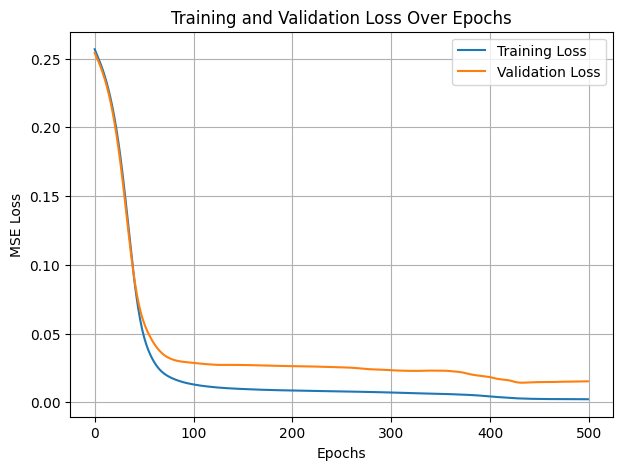

In [796]:
# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

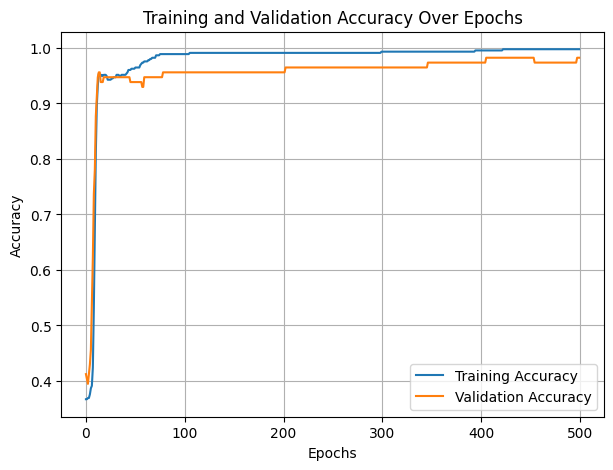

In [800]:
# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [798]:
y_valid_pred = model(t_u_val)
y_valid_pred = (y_valid_pred >= 0.5).float().numpy().ravel()

# Actual labels from the test dataset
y_valid = ytest.ravel().astype(int)


cnf_matrix = confusion_matrix(y_valid, y_valid_pred)
cnf_matrix

#Let's evaluate the model using model evaluation metrics such as accuracy, precision, and recall.
print("Accuracy:",metrics.accuracy_score(y_valid, y_valid_pred))
print("Precision:",metrics.precision_score(y_valid, y_valid_pred))
print("Recall:",metrics.recall_score(y_valid, y_valid_pred))
print("F1:",metrics.f1_score(y_valid, y_valid_pred))

report = classification_report(y_valid, y_valid_pred)
print(report)


Accuracy: 0.9824561403508771
Precision: 0.9787234042553191
Recall: 0.9787234042553191
F1: 0.9787234042553191
              precision    recall  f1-score   support

           0       0.99      0.99      0.99        67
           1       0.98      0.98      0.98        47

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



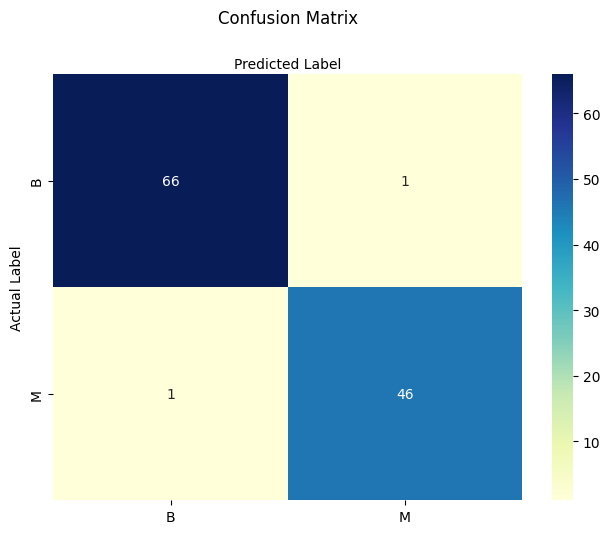

In [799]:
class_names = ['B', 'M']  # 0 = Benign, 1 = Malignant

fig, ax = plt.subplots()

tick_marks = np.arange(len(class_names))

plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

# Create heatmap
sns.heatmap(
    pd.DataFrame(cnf_matrix),
    annot=True,
    cmap="YlGnBu",
    fmt='g',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)

ax.xaxis.set_label_position("top")

plt.tight_layout()
plt.title('Confusion Matrix', y=1.1)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()